   mean radius  mean texture  mean perimeter  mean area  mean smoothness  \
0        17.99         10.38          122.80     1001.0          0.11840   
1        20.57         17.77          132.90     1326.0          0.08474   
2        19.69         21.25          130.00     1203.0          0.10960   
3        11.42         20.38           77.58      386.1          0.14250   
4        20.29         14.34          135.10     1297.0          0.10030   

   mean compactness  mean concavity  mean concave points  mean symmetry  \
0           0.27760          0.3001              0.14710         0.2419   
1           0.07864          0.0869              0.07017         0.1812   
2           0.15990          0.1974              0.12790         0.2069   
3           0.28390          0.2414              0.10520         0.2597   
4           0.13280          0.1980              0.10430         0.1809   

   mean fractal dimension  ...  worst radius  worst texture  worst perimeter  \
0           

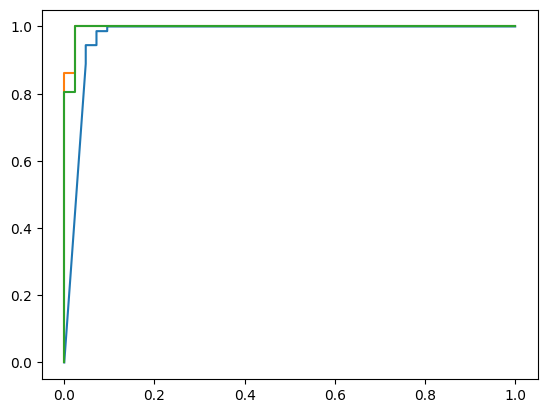

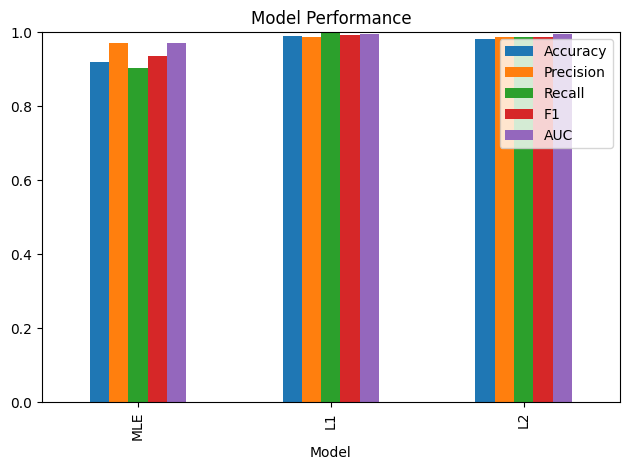

/tmp/ipykernel_3757/3885746964.py:65: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


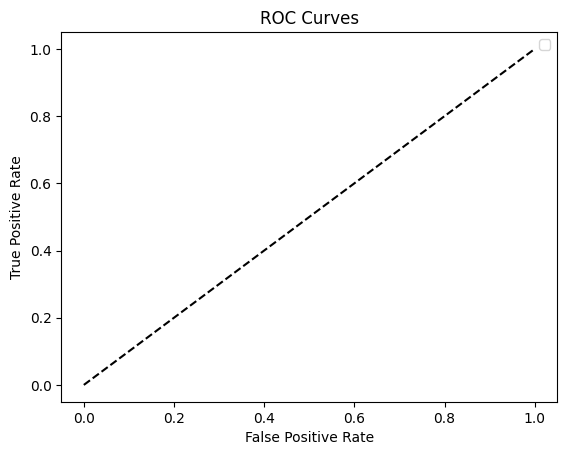

In [7]:

# ALGORITHM:
# 1. Load the Breast Cancer dataset and import libraries.
# 2. Split data into training and testing sets.
# 3. Standardize the features.
# 4. Train Logistic Regression using MLE, L1 and L2.
# 5. Predict classes and probabilities.
# 6. Calculate Accuracy, Precision, Recall, F1 and AUC.
# 7. Display confusion matrices and classification reports.
# 8. Compare model performance and coefficients.
# 9. Plot ROC curves and performance graphs.
# 10. Stop.

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import *

d = load_breast_cancer()
X, y = d.data, d.target
print(pd.DataFrame(X, columns=d.feature_names).head())
print("Shape:", X.shape, "Classes:", np.bincount(y))

a, b, c, e = train_test_split(
    X, y, test_size=.2, random_state=42, stratify=y)
s = StandardScaler()
a, b = s.fit_transform(a), s.transform(b)

models = {
    'MLE': LogisticRegression(penalty=None, max_iter=5000),
    'L1': LogisticRegression(penalty='l1', solver='liblinear', max_iter=5000),
    'L2': LogisticRegression(penalty='l2', max_iter=5000)
}
results = []
plt.figure()

for name, m in models.items():
    m.fit(a, c)
    pred, prob = m.predict(b), m.predict_proba(b)[:, 1]
    results.append([name, accuracy_score(e, pred),
                    precision_score(e, pred), recall_score(e, pred),
                    f1_score(e, pred), roc_auc_score(e, prob)])
    print('\n', name, '\n', confusion_matrix(e, pred))
    print(classification_report(e, pred))
    fpr, tpr, _ = roc_curve(e, prob)
    plt.plot(fpr, tpr, label=name)
    print("Nonzero coefficients:", np.count_nonzero(m.coef_))

r = pd.DataFrame(results, columns=[
    'Model', 'Accuracy', 'Precision', 'Recall', 'F1', 'AUC'])
print(r.round(3))
r.set_index('Model').plot(kind='bar', ylim=(0, 1))
plt.title('Model Performance')
plt.tight_layout()
plt.show()

plt.figure()
plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curves')
plt.legend()
plt.show()
